In [1]:
"""
D-RAMZI-based Photonic KAN for MNIST and Fashion-MNIST.

The experiment follows the supplied figure where the source is explicit:
    architecture: [784, 64, 10]
    loss: categorical cross-entropy
    optimizer: AdamW
    initial learning rate: 1e-2
    exponential learning-rate scheduler: gamma = 0.95
    epochs: 30

The supplied excerpt does not define the photonic edge function. This script
therefore implements a computationally practical D-RAMZI BASIS KAN:

    phi_oi(x) = w_linear[oi] * x
                + sum_k w_photonic[oik] * f_D-RAMZI,k(x)

A small bank of f_D-RAMZI,k curves is generated from the full physical D-RAMZI
model. Every KAN edge learns its own linear combination of those physical
transfer curves. This is analogous to a spline-basis KAN, except that the basis
functions are physically generated D-RAMZI responses.

The physical curves are stored in a dense lookup table (LUT). PyTorch evaluates
them with differentiable piecewise-linear interpolation. This avoids running a
carrier ODE or a neural surrogate on 50,816 edges for every image.
"""

from __future__ import annotations

import csv
import json
import math
import random
import time
from contextlib import nullcontext
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, List, Sequence, Tuple

import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp
from scipy.stats import qmc

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, Subset, random_split
from torchvision import datasets, transforms




# Configuração do Teste

1) **SEED** fixa permite reproduzir novamente o teste.
2) **DATASETS_TO_RUN** define os dados utilizados para treinamento. Nesse caso, usarei "MNIST" e "Fashin-MNIST".
3) **ARCHITECTURE** é uma tupla. Como as imagens de entradas tem 28x28 pixels, então são 784 entradas, que serão conectadas a 64 neurônios e gerarão 10 saídas.
4) O treinamento será realizado ao longo de 30 épocas (**EPOCHS**). Em outras palavras, os mesmos data sets entrarão na rede, e terão os parâmetros ajustados, 30 vezes.
5) **INITIAL_LR** é a taxa de aprendizado inicial. Conforme seja necessário maiores/menores taxas, a taxa de aprendizado será alterada. 
6) **LR_GAMMA** é a taxa com que a taxa de aprendizado é reduzida.
7) **WEIGHT_DECAY** regularização do AdamW.
8) **BATCH_SIZE** é o número de imagens que são trabalhadas simultaneamente pela rede. Paraleliza o processo. Ao invés de fazer 1 imagem por ver (série), fazer 256 imagens (paralelo) reduz o tempo de treinamento, mas requer mais poder de processamento.
9) **TEST_BATCH_SIZE** é a quantidade de imagens que são usadas para verificar a predição da rede, simultaneamente.
10) **NUM_WORKERS** indica quantos processos são utilizados para organizar as imagens.
11) **USE_AMP** permite usar precisão mista na GPU para acelerar o cálculo. Alguns números podem ter sua previsão reduzida, para liberar espaço de memória.
12) **GRAD_CLIP_NORM** limita a variação dos gradientes. Nesse caso, se um parâmetros variar muito, sua variação será limitada para evitar instabilidade.
13) **N_PHYSICAL_BASES** diz quantas curvas da unidade D-RAMZI serão utilizadas em cada conexão. Ao todo, teremos $(784\times64 + 64\times10)\times8$ curvas ao total.
14) **N_BASIS_CANDIDATES** é a quantidade de curvas que são possíveis candidatos. Nesse caso, temos 256 candidatos, das quais serão escolhidos apenas 8 (N_PHYSICAL_BASES).
15) **PHYSICAL_LUT_POINTS** é a resolução da tabela que armazena cada curva. Quanto maior, melhor a representação, porém mais poder computacional é requerido.
16) **USE_LINEAR_BYPASS** permite que seja usada uma contribuição $\omega x$, além das funções das unidades D-RAMZI. 

Note que:

\begin{equation}
\phi_{oi}(x) = \omega_{oi}^{linear}x + \sum_{k=1}^{8}\omega_{oik}^{fotônico}f_{D-RAMZI,k}(x), \text{onde:}
\end{equation}
* $x$ é o valor que chega pela conexão. Na primeira camada é o valor do pixel. Nas subsequentes é a saída do neurônio anterior.
* $i$ identifica a entrada
* $o$ identifica o neurônio que recebe essa entrada.
* $\omega_{oi}^{linear}x$ é a contribuição linear. Durante o treinamento $\omega_{oi}^{linear}$ é aprendido.
* $f_{D-RAMZI,k}(x)$ é a resposta da curva $k$ quando recebe $x$.
* $\omega_{oik}^{linear}$ é o peso que indica o quanto a curva $k$ contribui para aquela conexão.
* $\sum_{k=1}^8$ soma todas as 8 contribuições.

Os pesos são aprendidos pelo treinamento. Por outro lado, as curvas D-RAMZI são preparadas pelos modelos físicos e guardados em uma tabela. A rede apenas aprende a combinar essas curvas. As 8 curvas não significam 8 D-RAMZIs físicos para cada conexão. São 8 funções de resposta compartilhada, onde cada conexão aprende seus pesos. 

Diferentemente de redes neurais comuns, onde cada conexão tem apenas 1 peso, cada conexão irá aprender uma função $\phi_{oi}(x)$, formada por combinação de curvas da unidade D-RAMZI.

In [ ]:
SEED = 42

DATASETS_TO_RUN: Tuple[str, ...] = ("MNIST", "FashionMNIST")

ARCHITECTURE = (784, 64, 10)
EPOCHS = 30
INITIAL_LR = 1e-2
LR_GAMMA = 0.95

WEIGHT_DECAY = 1e-4

BATCH_SIZE = 256
TEST_BATCH_SIZE = 512
NUM_WORKERS = 4 
USE_AMP = True
GRAD_CLIP_NORM = 5.0

N_PHYSICAL_BASES = 8
N_BASIS_CANDIDATES = 256
PHYSICAL_LUT_POINTS = 4097
USE_LINEAR_BYPASS = True

HIDDEN_DROPOUT = 0.0

TRAIN_LIMIT: int | None = None
TEST_LIMIT: int | None = None
VALIDATION_SIZE = 5000

VALIDATE_STEADY_STATE = False

OUTPUT_ROOT = Path("dramzi_photonic_kan_results")
DATA_ROOT = Path("data")



# Definindo Seed e dispositivo usado para treinamento.

1) **set_seed** define manualmente uma semente para os geradores aleatórios (Python, Numpy e PyTorch). Caso tenha GPU disponível, também define a seed.
2) **select_device** é feita uma verificação para ver se o PyTorch consegue ou não usar uma GPU NVidia. Caso não tenha, PyTorch utilizará a CPU como dispositivo padrão.

In [3]:
def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def select_device() -> torch.device:
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    print("\n" + "=" * 80)
    print("DEVICE")
    print("=" * 80)
    print(f"PyTorch version: {torch.__version__}")
    print(f"PyTorch CUDA runtime: {torch.version.cuda}")
    print(f"CUDA available: {torch.cuda.is_available()}")
    print(f"Selected device: {device}")

    if device.type == "cuda":
        print(f"GPU: {torch.cuda.get_device_name(0)}")
        properties = torch.cuda.get_device_properties(0)
        print(f"VRAM: {properties.total_memory / 1024**3:.2f} GB")
        torch.backends.cudnn.benchmark = True
        torch.backends.cuda.matmul.allow_tf32 = True
        torch.backends.cudnn.allow_tf32 = True
    else:
        print(
            "WARNING: this will run on CPU. Install a CUDA-enabled PyTorch "
            "build to use an NVIDIA GPU."
        )

    return device

## Parâmetros físico da unidade D-RAMZI

In [ ]:
lambda0 = 1550e-9
neff0 = 2.3537
ng = 2.3537

FSR_nm = 20e-9
L = lambda0**2 / (ng * FSR_nm)

L_rr_1 = 2.0 * L
L_rr_2 = 2.0 * L

L_wvg1 = 4.0 * L
L_wvg2 = 50e-6 + 2.0 * L
L_wvg3 = 50e-6
L_wvg4 = 4.0 * L
L_wvg5 = 50e-6
L_wvg6 = 50e-6 + 2.0 * L

alpha1 = 0.80
alpha2 = 0.80

eta_fc = 1e-6
gamma_fc = 1e10
mu = 1e5
tau = 5e-9
xi = 1e40

delta_f = 2e9
delta_omega = 2.0 * np.pi * delta_f

P_max = 0.2e-3

r_coupler = 1.0 / np.sqrt(2.0)
t_coupler = np.sqrt(1.0 - r_coupler**2)

THETA_MIN = np.array([0.0, 0.0, 0.0, 0.0, 1.0], dtype=float)
THETA_MAX = np.array([2.0 * np.pi, 2.0 * np.pi, 2.0 * np.pi, 2.0 * np.pi, 20.0],dtype=float,)


ANCHOR_X2_THETA = np.array([3.066376309, 0.797166695, 5.031894120, 0.895402378, 5.730379698],dtype=float,)



# Funções Ópticas

In [ ]:
def beta_calc(lamb_vector: np.ndarray | float) -> np.ndarray:
    lamb_vector = np.asarray(lamb_vector, dtype=float)
    dneff_dlambda = (neff0 - ng) / lambda0
    neff = neff0 + dneff_dlambda * (lamb_vector - lambda0)
    return 2.0 * np.pi * neff / lamb_vector


def beta_mrr(
    lamb_vector: np.ndarray | float,
    Nc: np.ndarray | float,
) -> np.ndarray:
    lamb_vector = np.asarray(lamb_vector, dtype=float)
    Nc = np.asarray(Nc, dtype=float)
    dneff_dlambda = (neff0 - ng) / lambda0
    neff = (
        neff0
        + dneff_dlambda * (lamb_vector - lambda0)
        - eta_fc * Nc
    )
    return 2.0 * np.pi * neff / lamb_vector


def mrr_transfer(
    Nc: np.ndarray | float,
    ring_length: float,
    attenuation: float,
) -> np.ndarray:
    beta = beta_mrr(lambda0, Nc)
    round_trip = np.exp(-1j * beta * ring_length)
    numerator = np.conj(r_coupler) - attenuation * round_trip
    denominator = 1.0 - r_coupler * attenuation * round_trip
    return numerator / denominator


def wvg_transfer(length: float) -> complex:
    beta = float(beta_calc(lambda0))
    return np.exp(-1j * beta * length)


H_wvg1 = wvg_transfer(L_wvg1)
H_wvg2 = wvg_transfer(L_wvg2)
H_wvg3 = wvg_transfer(L_wvg3)
H_wvg4 = wvg_transfer(L_wvg4)
H_wvg5 = wvg_transfer(L_wvg5)
H_wvg6 = wvg_transfer(L_wvg6)


# EDO original e Solução Estacionária Algébrica

In [ ]:
def carrier_dynamics(t: float,state: np.ndarray,Pin: float,detuning: float,) -> List[float]:
    a_real, a_imag, Nc = state
    a_cav = a_real + 1j * a_imag
    intensity = np.abs(a_cav) ** 2

    da_dt = (-(1j * detuning + gamma_fc) * a_cav- 1j * eta_fc * Nc * a_cav- 1j * mu * np.sqrt(Pin))
    dNc_dt = -Nc / tau + xi * intensity**2

    return [float(da_dt.real), float(da_dt.imag), float(dNc_dt)]


def get_Nc_ss_ode(Pin: float, detuning: float = delta_omega) -> float:
    Pin = float(Pin)
    if Pin <= 0.0:
        return 0.0

    solution = solve_ivp(lambda t, y: carrier_dynamics(t, y, Pin, detuning),(0.0, 100e-9),[0.0, 0.0, 0.0],rtol=1e-9,atol=[1e-20, 1e-20, 1e-14],method="DOP853",)

    if not solution.success:
        raise RuntimeError(f"Carrier integration failed: {solution.message}")

    return float(solution.y[2, -1])


def get_Nc_ss(Pin: np.ndarray | float,detuning: float = delta_omega,newton_iterations: int = 14,) -> np.ndarray | float:
    
    Pin_array = np.asarray(Pin, dtype=float)
    scalar_input = Pin_array.ndim == 0
    P = np.atleast_1d(np.maximum(Pin_array, 0.0))

    A = tau * xi * (mu**4) * (P**2)
    base_denominator = gamma_fc**2 + detuning**2
    upper = A / (base_denominator**2)
    Nc = upper.copy()

    for _ in range(newton_iterations):
        shifted_detuning = detuning + eta_fc * Nc
        denominator = gamma_fc**2 + shifted_detuning**2
        function_value = Nc - A / (denominator**2)
        derivative = (1.0+ 4.0* A* eta_fc* shifted_detuning/ (denominator**3))
        proposal = Nc - function_value / derivative
        Nc = np.clip(proposal, 0.0, upper)

    Nc[P <= 0.0] = 0.0

    if scalar_input:
        return float(Nc[0])
    return Nc


def validate_steady_state_solver() -> None:
    print("\n" + "=" * 80)
    print("STEADY-STATE VALIDATION: ALGEBRAIC SOLVER VS ODE")
    print("=" * 80)

    for power in [0.0, 0.05e-3, 0.10e-3, 0.20e-3]:
        algebraic = get_Nc_ss(power)
        ode = get_Nc_ss_ode(power)
        relative_error = abs(algebraic - ode) / max(abs(ode), 1e-30)
        print(
            f"Pin={power:.3e} W | Nc_ODE={ode:.9e} | "
            f"Nc_alg={algebraic:.9e} | relative error={relative_error:.3e}"
        )

# Unidade D-RAMZI Completa em 1550nm

In [ ]:
def canonicalize_theta(theta: np.ndarray) -> np.ndarray:
    theta = np.asarray(theta, dtype=float).copy()
    theta[:4] = np.mod(theta[:4], 2.0 * np.pi)
    theta[4] = np.clip(theta[4], THETA_MIN[4], THETA_MAX[4])
    return theta


def dramzi_power_curve(
    x: np.ndarray,
    theta: np.ndarray,
    Nc1_cache: np.ndarray | None = None,
) -> np.ndarray:
    """Physical D-RAMZI output power Pout(x) for x in [0, 1]."""
    x = np.asarray(x, dtype=float)
    theta = canonicalize_theta(theta)
    phi_1a, phi_1b, phi_2a, phi_2b, G_SOA = theta

    Pin = np.clip(x, 0.0, 1.0) * P_max
    Ein = np.sqrt(Pin).astype(complex)

    if Nc1_cache is None:
        Nc1 = get_Nc_ss(Pin)
    else:
        Nc1 = np.asarray(Nc1_cache, dtype=float)
        if Nc1.shape != Pin.shape:
            raise ValueError("Nc1_cache must have the same shape as x.")

    # RAMZI 1
    arm_top = mrr_transfer(Nc1, L_rr_1, alpha1) * Ein / np.sqrt(2.0)
    arm_bottom = H_wvg1 * Ein / np.sqrt(2.0)
    arm_bottom *= np.exp(1j * phi_1a)

    after_coupler_top = r_coupler * arm_top - 1j * t_coupler * arm_bottom
    after_coupler_bottom = -1j * t_coupler * arm_top + r_coupler * arm_bottom

    arm_top = H_wvg2 * after_coupler_top
    arm_bottom = H_wvg3 * after_coupler_bottom * np.exp(1j * phi_1b)
    E1 = (arm_top + arm_bottom) / np.sqrt(2.0)

    # SOA
    E2 = np.sqrt(G_SOA) * E1
    Pin2 = np.abs(E2) ** 2

    # RAMZI 2
    Nc2 = get_Nc_ss(Pin2)
    arm_top = mrr_transfer(Nc2, L_rr_2, alpha2) * E2 / np.sqrt(2.0)
    arm_bottom = H_wvg4 * E2 / np.sqrt(2.0)
    arm_bottom *= np.exp(1j * phi_2a)

    after_coupler_top = r_coupler * arm_top - 1j * t_coupler * arm_bottom
    after_coupler_bottom = -1j * t_coupler * arm_top + r_coupler * arm_bottom

    arm_top = H_wvg5 * after_coupler_top
    arm_bottom = H_wvg6 * after_coupler_bottom * np.exp(1j * phi_2b)
    Eout = (arm_top + arm_bottom) / np.sqrt(2.0)

    return np.abs(Eout) ** 2


# Conjunto de curvas D-RAMZI

1) **PhysicalBasisBank** é onde armazena todas as curvas.
    * **x_grid** são os valores de entrada usados para desenhar cada curva, variando de 0 a 1.
    * **theta_bank** são os parâmetros do D-RAMZI para as curvas escolhidas.
    * **rms_scale** são curvas em escala original.
    * **normalized_curves** são as curvas selecionadas já normalizadas.
    * **interpolation_mse** e **interpolation_max_error** são as medidas de error (ponto a ponto e máximo, respectivamente) dado a interpolação na tabela.
2) **normalize_physical_curve** retorna a curva normalizada e a escala utilizada, baseando-se no RMS.
3) **select_diverse_curves** seleciona as 8 curvas (N_PHYSICAL_BASES) mais distintas entre si. O argumento, **curves**, é uma matriz com todas as 256 curvas geradas (N_BASIS_CANDIDATES). 

    Vamos imaginar que temos apenas 3 pontos por curva de tal forma que:

    \begin{equation}
    \text{curves} = \begin{bmatrix}v_1 = {\begin{bmatrix} 1,0,0 \end{bmatrix}}\\v_2 = {\begin{bmatrix} 10,0,0 \end{bmatrix}}\\... \end{bmatrix}
    \end{equation}

    Note que, se tomarmos o vetor unitário $\frac{\vec{v_1}}{|\vec{v_1}|}$ e $\frac{\vec{v_2}}{|\vec{v_2}|}$, ambos passam a possuir mesma direção, sentido e intensidade, apesar de $\vec{v_1}\neq\vec{v_2}$. Não teria necessidade de, ao escolher $\vec{v_1}$, escolher $\vec{v_2}$, ou vice-versa. É nessa ideia que o algoritmo se baseia: 
    1) Calcular o vetor unitário de cada curva.
    2) A primeira curva é sempre escolhida, e passa a servir como referência de "quão igual" as outras curvas são.
    3) Com a primeira curva já escolhida, comparamos todas as demais curvas com a referência, por meio do cálculo de projeção. 
    4) A curva que possuir maior contraste com relação a outras curvas escolhidas, será a nova escolhida
    5) Repetimos o processo até termos as 8 melhores curvas.

    Em suma, sempre é priorizada a curva cujo vetor tem a maior componente perpendicular ao espaço coberto pelos vetores já escolhidos.

In [ ]:
@dataclass
class PhysicalBasisBank:
    x_grid: np.ndarray
    theta_bank: np.ndarray
    rms_scale: np.ndarray
    normalized_curves: np.ndarray
    interpolation_mse: np.ndarray
    interpolation_max_error: np.ndarray


def normalize_physical_curve(raw_curve: np.ndarray) -> Tuple[np.ndarray, float] | None:
    """RMS normalize while preserving f(0)=0."""
    curve = np.asarray(raw_curve, dtype=float) - float(raw_curve[0])
    rms = float(np.sqrt(np.mean(curve**2)))
    if not np.isfinite(rms) or rms < 1e-14:
        return None
    return curve / rms, rms


def sobol_theta_candidates(n: int, seed: int) -> np.ndarray:
    exponent = int(math.ceil(math.log2(max(n, 1))))
    sampler = qmc.Sobol(d=5, scramble=True, seed=seed)
    unit_points = sampler.random_base2(m=exponent)[:n]
    return THETA_MIN + unit_points * (THETA_MAX - THETA_MIN)


def select_diverse_curves(curves: np.ndarray, n_select: int) -> List[int]:
    """Greedy Gram-Schmidt selection, with the x^2 anchor at index 0."""
    if curves.shape[0] < n_select:
        raise ValueError("Not enough valid D-RAMZI curves.")

    vectors = curves / np.maximum(np.linalg.norm(curves, axis=1, keepdims=True), 1e-12)

    selected = [0]
    q_vectors = [vectors[0] / max(np.linalg.norm(vectors[0]), 1e-12)]
    available = np.ones(curves.shape[0], dtype=bool)
    available[0] = False

    while len(selected) < n_select:
        Q = np.stack(q_vectors, axis=0)
        projection = (vectors @ Q.T) @ Q
        residual = vectors - projection
        scores = np.linalg.norm(residual, axis=1)
        scores[~available] = -np.inf

        index = int(np.argmax(scores))
        if not np.isfinite(scores[index]):
            raise RuntimeError("Could not select diverse D-RAMZI bases.")

        residual_norm = float(scores[index])
        q = (residual[index] / residual_norm if residual_norm > 1e-10 else vectors[index])

        selected.append(index)
        q_vectors.append(q)
        available[index] = False

    return selected


def build_physical_basis_bank(n_bases: int,n_candidates: int,lut_points: int,seed: int,) -> PhysicalBasisBank:
    print("\n" + "=" * 80)
    print("BUILDING PHYSICAL D-RAMZI BASIS BANK")
    print("=" * 80)

    if lut_points < 2:
        raise ValueError("PHYSICAL_LUT_POINTS must be at least 2.")

    x_grid = np.linspace(0.0, 1.0, lut_points)
    Nc1_cache = get_Nc_ss(x_grid * P_max)

    random_candidates = sobol_theta_candidates(max(n_candidates - 1, 1), seed)
    theta_candidates = np.vstack([ANCHOR_X2_THETA[None, :], random_candidates])

    valid_theta: List[np.ndarray] = []
    valid_curves: List[np.ndarray] = []
    valid_rms: List[float] = []

    for index, theta in enumerate(theta_candidates):
        raw_curve = dramzi_power_curve(x_grid, theta, Nc1_cache=Nc1_cache)
        normalized_result = normalize_physical_curve(raw_curve)

        if normalized_result is not None:
            normalized_curve, rms = normalized_result
            if np.all(np.isfinite(normalized_curve)):
                valid_theta.append(canonicalize_theta(theta))
                valid_curves.append(normalized_curve)
                valid_rms.append(rms)

        if (index + 1) % 64 == 0 or index == len(theta_candidates) - 1:
            print(
                f"Candidates evaluated: {index + 1}/{len(theta_candidates)} | "
                f"valid: {len(valid_curves)}"
            )

    theta_array = np.asarray(valid_theta)
    curve_array = np.asarray(valid_curves)
    rms_array = np.asarray(valid_rms)

    selected_indices = select_diverse_curves(curve_array, n_bases)
    theta_bank = theta_array[selected_indices]
    normalized_curves = curve_array[selected_indices]
    selected_rms = rms_array[selected_indices]

    midpoint_grid = 0.5 * (x_grid[:-1] + x_grid[1:])
    Nc1_midpoint = get_Nc_ss(midpoint_grid * P_max)
    interpolation_mse: List[float] = []
    interpolation_max_error: List[float] = []

    for theta, rms, lut_curve in zip(theta_bank, selected_rms, normalized_curves):
        raw_midpoint = dramzi_power_curve(
            midpoint_grid, theta, Nc1_cache=Nc1_midpoint
        )
        physical_midpoint = (raw_midpoint - 0.0) / rms
        interpolated_midpoint = np.interp(midpoint_grid, x_grid, lut_curve)
        error = interpolated_midpoint - physical_midpoint
        interpolation_mse.append(float(np.mean(error**2)))
        interpolation_max_error.append(float(np.max(np.abs(error))))

    mse_array = np.asarray(interpolation_mse)
    max_error_array = np.asarray(interpolation_max_error)

    print(f"Selected physical bases: {n_bases}")
    print(f"LUT points per basis: {lut_points}")
    print(f"Mean midpoint interpolation MSE: {mse_array.mean():.3e}")
    print(f"Worst midpoint interpolation MSE: {mse_array.max():.3e}")
    print(f"Worst midpoint max error: {max_error_array.max():.3e}")

    return PhysicalBasisBank(
        x_grid=x_grid,
        theta_bank=theta_bank,
        rms_scale=selected_rms,
        normalized_curves=normalized_curves,
        interpolation_mse=mse_array,
        interpolation_max_error=max_error_array,
    )


def save_basis_bank(bank: PhysicalBasisBank, output_dir: Path) -> None:
    output_dir.mkdir(parents=True, exist_ok=True)

    np.save(output_dir / "theta_bank.npy", bank.theta_bank)
    np.save(output_dir / "lut_curves.npy", bank.normalized_curves)
    np.save(output_dir / "x_grid.npy", bank.x_grid)

    with (output_dir / "theta_bank.csv").open("w", newline="") as file:
        writer = csv.writer(file)
        writer.writerow(
            [
                "basis",
                "phi_1a",
                "phi_1b",
                "phi_2a",
                "phi_2b",
                "G_SOA",
                "rms_power_scale",
                "interpolation_mse",
                "interpolation_max_error",
            ]
        )
        for index, theta in enumerate(bank.theta_bank):
            writer.writerow(
                [
                    index,
                    *theta.tolist(),
                    bank.rms_scale[index],
                    bank.interpolation_mse[index],
                    bank.interpolation_max_error[index],
                ]
            )

    plt.figure(figsize=(9, 6))
    for index, curve in enumerate(bank.normalized_curves):
        plt.plot(bank.x_grid, curve, linewidth=1.8, label=f"Basis {index}")
    plt.xlabel("Normalized optical input x")
    plt.ylabel("RMS-normalized D-RAMZI response")
    plt.title("Physical D-RAMZI basis bank")
    plt.grid(True)
    plt.legend(ncol=2)
    plt.tight_layout()
    plt.savefig(output_dir / "physical_basis_bank.png", dpi=200)
    plt.close()

In [8]:
a= np.array([0,1,2])
print(0.5*a[:-1]+0.5*a[1:])

[0.5 1.5]


In [ ]:





# ============================================================================
# 8. DIFFERENTIABLE D-RAMZI LUT
# ============================================================================


class DRAMZILUTBank(nn.Module):
    """Evaluate all fixed D-RAMZI curves by linear LUT interpolation."""

    def __init__(self, normalized_curves: np.ndarray) -> None:
        super().__init__()
        curves = np.asarray(normalized_curves, dtype=np.float32)
        if curves.ndim != 2:
            raise ValueError("normalized_curves must have shape [K, M].")

        # Table shape [M, K] makes table[index] return [..., K].
        table = torch.from_numpy(curves.T.copy())
        self.register_buffer("table", table)

    @property
    def n_points(self) -> int:
        return int(self.table.shape[0])

    @property
    def n_bases(self) -> int:
        return int(self.table.shape[1])

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x shape: [B, I], with normalized power in [0, 1].
        x = torch.clamp(x, 0.0, 1.0)
        position = x * float(self.n_points - 1)

        lower_index = torch.floor(position).to(torch.long)
        lower_index = torch.clamp(lower_index, 0, self.n_points - 2)
        upper_index = lower_index + 1

        fraction = (position - lower_index.to(position.dtype)).unsqueeze(-1)
        lower_value = self.table[lower_index]
        upper_value = self.table[upper_index]

        return lower_value + fraction * (upper_value - lower_value)


# ============================================================================
# 9. D-RAMZI BASIS KAN LAYER
# ============================================================================


class DRAMZIKANLayer(nn.Module):
    """
    KAN layer with D-RAMZI basis edge functions.

        y_o = sum_i phi_oi(x_i) + bias_o
        phi_oi(x) = w_linear[oi] x + sum_k w_photonic[oik] f_k(x)
    """

    def __init__(
        self,
        in_features: int,
        out_features: int,
        basis_bank: DRAMZILUTBank,
        use_linear_bypass: bool = True,
    ) -> None:
        super().__init__()
        self.in_features = int(in_features)
        self.out_features = int(out_features)
        self.basis_bank = basis_bank
        self.use_linear_bypass = bool(use_linear_bypass)

        self.photonic_weight = nn.Parameter(
            torch.empty(out_features, in_features, basis_bank.n_bases)
        )

        if self.use_linear_bypass:
            self.linear_weight = nn.Parameter(
                torch.empty(out_features, in_features)
            )
        else:
            self.register_parameter("linear_weight", None)

        self.bias = nn.Parameter(torch.zeros(out_features))
        self.reset_parameters()

    def reset_parameters(self) -> None:
        with torch.no_grad():
            photonic_flat = self.photonic_weight.view(self.out_features, -1)
            gain = 1.0 / math.sqrt(2.0) if self.linear_weight is not None else 1.0
            nn.init.xavier_uniform_(photonic_flat, gain=gain)
            if self.linear_weight is not None:
                nn.init.xavier_uniform_(self.linear_weight, gain=gain)
            nn.init.zeros_(self.bias)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if x.ndim != 2 or x.shape[1] != self.in_features:
            raise ValueError(
                f"Expected [batch, {self.in_features}], got {tuple(x.shape)}."
            )

        basis_values = self.basis_bank(x)  # [B, I, K]
        basis_flat = basis_values.flatten(start_dim=1)
        weight_flat = self.photonic_weight.flatten(start_dim=1)
        output = F.linear(basis_flat, weight_flat, self.bias)

        if self.linear_weight is not None:
            output = output + F.linear(x, self.linear_weight)

        return output


# ============================================================================
# 10. TWO-LAYER [784, 64, 10] PHOTONIC KAN
# ============================================================================


class DRAMZIPhotonicKAN(nn.Module):
    def __init__(
        self,
        normalized_curves: np.ndarray,
        hidden_features: int = 64,
        n_classes: int = 10,
        dropout: float = 0.0,
        use_linear_bypass: bool = True,
    ) -> None:
        super().__init__()

        bank1 = DRAMZILUTBank(normalized_curves)
        bank2 = DRAMZILUTBank(normalized_curves)

        self.layer1 = DRAMZIKANLayer(
            784,
            hidden_features,
            bank1,
            use_linear_bypass=use_linear_bypass,
        )
        self.hidden_norm = nn.LayerNorm(hidden_features)
        self.hidden_dropout = nn.Dropout(dropout)
        self.layer2 = DRAMZIKANLayer(
            hidden_features,
            n_classes,
            bank2,
            use_linear_bypass=use_linear_bypass,
        )

    def forward(self, images: torch.Tensor) -> torch.Tensor:
        x = images.flatten(start_dim=1)
        hidden = self.layer1(x)

        # The second D-RAMZI layer requires a normalized optical input.
        hidden = torch.sigmoid(self.hidden_norm(hidden))
        hidden = self.hidden_dropout(hidden)

        return self.layer2(hidden)


# ============================================================================
# 11. DATASETS AND LOADERS
# ============================================================================


def maybe_limit_dataset(dataset: Dataset, limit: int | None, seed: int) -> Dataset:
    if limit is None or limit >= len(dataset):
        return dataset
    generator = torch.Generator().manual_seed(seed)
    indices = torch.randperm(len(dataset), generator=generator)[:limit].tolist()
    return Subset(dataset, indices)


def load_dataset(name: str) -> Tuple[Dataset, Dataset]:
    transform = transforms.ToTensor()

    if name == "MNIST":
        train_full = datasets.MNIST(
            root=str(DATA_ROOT), train=True, download=True, transform=transform
        )
        test_set = datasets.MNIST(
            root=str(DATA_ROOT), train=False, download=True, transform=transform
        )
    elif name == "FashionMNIST":
        train_full = datasets.FashionMNIST(
            root=str(DATA_ROOT), train=True, download=True, transform=transform
        )
        test_set = datasets.FashionMNIST(
            root=str(DATA_ROOT), train=False, download=True, transform=transform
        )
    else:
        raise ValueError(f"Unsupported dataset: {name}")

    return (
        maybe_limit_dataset(train_full, TRAIN_LIMIT, SEED),
        maybe_limit_dataset(test_set, TEST_LIMIT, SEED + 1),
    )


def split_train_validation(dataset: Dataset) -> Tuple[Dataset, Dataset]:
    validation_size = min(VALIDATION_SIZE, max(len(dataset) // 10, 1))
    train_size = len(dataset) - validation_size
    if train_size <= 0:
        raise ValueError("Dataset is too small for the requested validation split.")

    generator = torch.Generator().manual_seed(SEED)
    return random_split(dataset, [train_size, validation_size], generator=generator)


def make_loaders(
    dataset_name: str,
    device: torch.device,
) -> Tuple[DataLoader, DataLoader, DataLoader]:
    train_full, test_set = load_dataset(dataset_name)
    train_set, validation_set = split_train_validation(train_full)

    loader_kwargs = {
        "num_workers": NUM_WORKERS,
        "pin_memory": device.type == "cuda",
        "persistent_workers": NUM_WORKERS > 0,
    }

    train_loader = DataLoader(
        train_set,
        batch_size=BATCH_SIZE,
        shuffle=True,
        drop_last=False,
        **loader_kwargs,
    )
    validation_loader = DataLoader(
        validation_set,
        batch_size=TEST_BATCH_SIZE,
        shuffle=False,
        drop_last=False,
        **loader_kwargs,
    )
    test_loader = DataLoader(
        test_set,
        batch_size=TEST_BATCH_SIZE,
        shuffle=False,
        drop_last=False,
        **loader_kwargs,
    )

    print(
        f"{dataset_name}: train={len(train_set)}, "
        f"validation={len(validation_set)}, test={len(test_set)}"
    )
    return train_loader, validation_loader, test_loader


# ============================================================================
# 12. TRAINING UTILITIES
# ============================================================================


@dataclass
class EpochMetrics:
    epoch: int
    learning_rate: float
    train_loss: float
    train_accuracy: float
    validation_loss: float
    validation_accuracy: float
    test_loss: float
    test_accuracy: float
    seconds: float


def autocast_context(device: torch.device):
    if USE_AMP and device.type == "cuda":
        return torch.autocast(device_type="cuda", dtype=torch.float16)
    return nullcontext()


def make_grad_scaler(device: torch.device):
    enabled = USE_AMP and device.type == "cuda"
    try:
        return torch.amp.GradScaler("cuda", enabled=enabled)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=enabled)


def accuracy_count(logits: torch.Tensor, labels: torch.Tensor) -> int:
    return int((logits.argmax(dim=1) == labels).sum().item())


def train_one_epoch(
    model: nn.Module,
    loader: DataLoader,
    optimizer: torch.optim.Optimizer,
    scaler,
    device: torch.device,
) -> Tuple[float, float]:
    model.train()
    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        with autocast_context(device):
            logits = model(images)
            loss = F.cross_entropy(logits, labels)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP_NORM)
        scaler.step(optimizer)
        scaler.update()

        batch_size = labels.shape[0]
        total_loss += float(loss.item()) * batch_size
        total_correct += accuracy_count(logits.detach(), labels)
        total_examples += batch_size

    return total_loss / total_examples, total_correct / total_examples


@torch.no_grad()
def evaluate(
    model: nn.Module,
    loader: DataLoader,
    device: torch.device,
) -> Tuple[float, float, np.ndarray]:
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_examples = 0
    confusion = np.zeros((10, 10), dtype=np.int64)

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with autocast_context(device):
            logits = model(images)
            loss = F.cross_entropy(logits, labels)

        predictions = logits.argmax(dim=1)
        batch_size = labels.shape[0]

        total_loss += float(loss.item()) * batch_size
        total_correct += int((predictions == labels).sum().item())
        total_examples += batch_size

        true_np = labels.cpu().numpy()
        pred_np = predictions.cpu().numpy()
        np.add.at(confusion, (true_np, pred_np), 1)

    return (
        total_loss / total_examples,
        total_correct / total_examples,
        confusion,
    )


def count_parameters(model: nn.Module) -> int:
    return sum(parameter.numel() for parameter in model.parameters())


def save_history_csv(history: Sequence[EpochMetrics], path: Path) -> None:
    with path.open("w", newline="") as file:
        writer = csv.writer(file)
        writer.writerow(
            [
                "epoch",
                "learning_rate",
                "train_loss",
                "train_accuracy",
                "validation_loss",
                "validation_accuracy",
                "test_loss",
                "test_accuracy",
                "seconds",
            ]
        )
        for item in history:
            writer.writerow(
                [
                    item.epoch,
                    item.learning_rate,
                    item.train_loss,
                    item.train_accuracy,
                    item.validation_loss,
                    item.validation_accuracy,
                    item.test_loss,
                    item.test_accuracy,
                    item.seconds,
                ]
            )


def load_checkpoint(path: Path, device: torch.device) -> dict:
    try:
        return torch.load(path, map_location=device, weights_only=False)
    except TypeError:
        return torch.load(path, map_location=device)


# ============================================================================
# 13. PLOTS
# ============================================================================


def plot_dataset_history(
    dataset_name: str,
    history: Sequence[EpochMetrics],
    output_dir: Path,
) -> None:
    epochs = np.array([item.epoch for item in history])
    train_loss = np.array([item.train_loss for item in history])
    validation_loss = np.array([item.validation_loss for item in history])
    test_loss = np.array([item.test_loss for item in history])
    train_accuracy = np.array([item.train_accuracy for item in history])
    validation_accuracy = np.array([item.validation_accuracy for item in history])
    test_accuracy = np.array([item.test_accuracy for item in history])

    plt.figure(figsize=(8, 5))
    plt.plot(epochs, train_loss, linewidth=2, label="Train")
    plt.plot(epochs, validation_loss, linewidth=2, label="Validation")
    plt.plot(epochs, test_loss, linewidth=2, label="Test")
    plt.xlabel("Epoch")
    plt.ylabel("Cross-entropy loss")
    plt.yscale("log")
    plt.title(f"{dataset_name} - loss")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.savefig(output_dir / "loss.png", dpi=200)
    plt.close()

    plt.figure(figsize=(8, 5))
    plt.plot(epochs, 100.0 * train_accuracy, linewidth=2, label="Train")
    plt.plot(epochs, 100.0 * validation_accuracy, linewidth=2, label="Validation")
    plt.plot(epochs, 100.0 * test_accuracy, linewidth=2, label="Test")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy [%]")
    plt.title(f"{dataset_name} - accuracy")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.savefig(output_dir / "accuracy.png", dpi=200)
    plt.close()

    # A curve resembling the supplied figure: test accuracy and test loss.
    figure, accuracy_axis = plt.subplots(figsize=(8, 5))
    loss_axis = accuracy_axis.twinx()

    accuracy_line = accuracy_axis.plot(
        epochs, test_accuracy, linewidth=2, label="Accuracy"
    )[0]
    loss_line = loss_axis.plot(epochs, test_loss, linewidth=2, label="Loss")[0]

    accuracy_axis.set_xlabel("Epoch")
    accuracy_axis.set_ylabel("Accuracy")
    loss_axis.set_ylabel("Loss")
    accuracy_axis.set_title(dataset_name)
    accuracy_axis.grid(True)
    accuracy_axis.legend(
        [accuracy_line, loss_line], ["Accuracy", "Loss"], loc="best"
    )

    final_start = max(len(epochs) - 20, 0)
    inset = accuracy_axis.inset_axes([0.54, 0.48, 0.42, 0.42])
    inset_loss = inset.twinx()
    inset.plot(epochs[final_start:], test_accuracy[final_start:], linewidth=1.2)
    inset_loss.plot(epochs[final_start:], test_loss[final_start:], linewidth=1.2)
    inset.tick_params(labelsize=7)
    inset_loss.tick_params(labelsize=7)
    inset.grid(True)

    figure.tight_layout()
    figure.savefig(output_dir / "paper_style_curve.png", dpi=220)
    plt.close(figure)


def plot_confusion_matrix(
    confusion: np.ndarray,
    dataset_name: str,
    output_path: Path,
) -> None:
    row_sum = np.maximum(confusion.sum(axis=1, keepdims=True), 1)
    normalized = confusion / row_sum

    plt.figure(figsize=(7, 6))
    plt.imshow(normalized, origin="upper", aspect="auto", vmin=0.0, vmax=1.0)
    plt.colorbar(label="Fraction")
    plt.xlabel("Predicted class")
    plt.ylabel("True class")
    plt.title(f"{dataset_name} - normalized confusion matrix")
    plt.xticks(range(10))
    plt.yticks(range(10))
    plt.tight_layout()
    plt.savefig(output_path, dpi=200)
    plt.close()


def plot_combined_paper_figure(
    histories: Dict[str, Sequence[EpochMetrics]],
    output_path: Path,
) -> None:
    names = list(histories.keys())
    if not names:
        return

    figure, axes = plt.subplots(1, len(names), figsize=(7 * len(names), 5))
    if len(names) == 1:
        axes = [axes]

    for panel_index, (axis, name) in enumerate(zip(axes, names)):
        history = histories[name]
        epochs = np.array([item.epoch for item in history])
        accuracy = np.array([item.test_accuracy for item in history])
        loss = np.array([item.test_loss for item in history])

        loss_axis = axis.twinx()
        accuracy_line = axis.plot(
            epochs, accuracy, linewidth=2, label="Accuracy"
        )[0]
        loss_line = loss_axis.plot(epochs, loss, linewidth=2, label="Loss")[0]

        axis.set_xlabel("Epoch")
        axis.set_ylabel("Accuracy")
        loss_axis.set_ylabel("Loss")
        axis.set_title(f"({chr(97 + panel_index)}) {name}")
        axis.grid(True)
        axis.legend(
            [accuracy_line, loss_line],
            ["Accuracy", "Loss"],
            loc="lower right",
        )

        final_start = max(len(epochs) - 20, 0)
        inset = axis.inset_axes([0.50, 0.48, 0.46, 0.42])
        inset_loss = inset.twinx()
        inset.plot(epochs[final_start:], accuracy[final_start:], linewidth=1.0)
        inset_loss.plot(epochs[final_start:], loss[final_start:], linewidth=1.0)
        inset.tick_params(labelsize=7)
        inset_loss.tick_params(labelsize=7)
        inset.grid(True)

    figure.suptitle("D-RAMZI-based Photonic KAN")
    figure.tight_layout()
    figure.savefig(output_path, dpi=220)
    plt.close(figure)


# ============================================================================
# 14. TRAIN ONE DATASET
# ============================================================================


def train_dataset(
    dataset_name: str,
    normalized_curves: np.ndarray,
    device: torch.device,
) -> Tuple[List[EpochMetrics], Dict[str, float]]:
    output_dir = OUTPUT_ROOT / dataset_name
    output_dir.mkdir(parents=True, exist_ok=True)

    train_loader, validation_loader, test_loader = make_loaders(
        dataset_name, device
    )

    model = DRAMZIPhotonicKAN(
        normalized_curves=normalized_curves,
        hidden_features=ARCHITECTURE[1],
        n_classes=ARCHITECTURE[2],
        dropout=HIDDEN_DROPOUT,
        use_linear_bypass=USE_LINEAR_BYPASS,
    ).to(device)

    print("\n" + "=" * 80)
    print(f"TRAINING {dataset_name}")
    print("=" * 80)
    print(f"Architecture: {ARCHITECTURE}")
    print(f"Trainable parameters: {count_parameters(model):,}")
    print(f"Physical D-RAMZI bases: {normalized_curves.shape[0]}")
    print(f"LUT points: {normalized_curves.shape[1]}")
    print(f"AdamW initial lr: {INITIAL_LR:.3e}")
    print(f"AdamW weight decay: {WEIGHT_DECAY:.3e}")
    print(f"ExponentialLR gamma: {LR_GAMMA}")
    print(f"Epochs: {EPOCHS}")

    optimizer = torch.optim.AdamW(
        model.parameters(), lr=INITIAL_LR, weight_decay=WEIGHT_DECAY
    )
    scheduler = torch.optim.lr_scheduler.ExponentialLR(
        optimizer, gamma=LR_GAMMA
    )
    scaler = make_grad_scaler(device)

    history: List[EpochMetrics] = []
    best_validation_accuracy = -np.inf
    best_epoch = 0
    best_checkpoint_path = output_dir / "best_validation_model.pt"

    for epoch in range(1, EPOCHS + 1):
        epoch_start = time.perf_counter()
        current_lr = float(optimizer.param_groups[0]["lr"])

        train_loss, train_accuracy = train_one_epoch(
            model, train_loader, optimizer, scaler, device
        )
        validation_loss, validation_accuracy, _ = evaluate(
            model, validation_loader, device
        )
        test_loss, test_accuracy, _ = evaluate(model, test_loader, device)

        elapsed = time.perf_counter() - epoch_start
        metrics = EpochMetrics(
            epoch=epoch,
            learning_rate=current_lr,
            train_loss=train_loss,
            train_accuracy=train_accuracy,
            validation_loss=validation_loss,
            validation_accuracy=validation_accuracy,
            test_loss=test_loss,
            test_accuracy=test_accuracy,
            seconds=elapsed,
        )
        history.append(metrics)

        if validation_accuracy > best_validation_accuracy:
            best_validation_accuracy = validation_accuracy
            best_epoch = epoch
            torch.save(
                {
                    "dataset": dataset_name,
                    "epoch": epoch,
                    "architecture": ARCHITECTURE,
                    "model_state_dict": model.state_dict(),
                    "optimizer_state_dict": optimizer.state_dict(),
                    "validation_accuracy": validation_accuracy,
                    "test_accuracy_at_checkpoint": test_accuracy,
                },
                best_checkpoint_path,
            )

        scheduler.step()

        print(
            f"Epoch {epoch:02d}/{EPOCHS} | "
            f"train loss={train_loss:.5f} acc={100*train_accuracy:6.2f}% | "
            f"val loss={validation_loss:.5f} acc={100*validation_accuracy:6.2f}% | "
            f"test loss={test_loss:.5f} acc={100*test_accuracy:6.2f}% | "
            f"lr={current_lr:.3e} | {elapsed:.1f}s"
        )

    torch.save(
        {
            "dataset": dataset_name,
            "epoch": EPOCHS,
            "architecture": ARCHITECTURE,
            "model_state_dict": model.state_dict(),
        },
        output_dir / "final_model.pt",
    )

    final_test_loss, final_test_accuracy, final_confusion = evaluate(
        model, test_loader, device
    )

    best_checkpoint = load_checkpoint(best_checkpoint_path, device)
    model.load_state_dict(best_checkpoint["model_state_dict"])
    best_test_loss, best_test_accuracy, best_confusion = evaluate(
        model, test_loader, device
    )

    save_history_csv(history, output_dir / "history.csv")
    plot_dataset_history(dataset_name, history, output_dir)
    plot_confusion_matrix(
        best_confusion,
        dataset_name,
        output_dir / "best_validation_confusion_matrix.png",
    )
    plot_confusion_matrix(
        final_confusion,
        dataset_name,
        output_dir / "final_confusion_matrix.png",
    )

    summary = {
        "dataset": dataset_name,
        "architecture": list(ARCHITECTURE),
        "epochs": EPOCHS,
        "optimizer": "AdamW",
        "initial_learning_rate": INITIAL_LR,
        "lr_gamma": LR_GAMMA,
        "weight_decay": WEIGHT_DECAY,
        "n_physical_bases": int(normalized_curves.shape[0]),
        "lut_points": int(normalized_curves.shape[1]),
        "trainable_parameters": count_parameters(model),
        "best_validation_epoch": best_epoch,
        "best_validation_accuracy": float(best_validation_accuracy),
        "test_accuracy_at_best_validation": float(best_test_accuracy),
        "test_loss_at_best_validation": float(best_test_loss),
        "final_test_accuracy": float(final_test_accuracy),
        "final_test_loss": float(final_test_loss),
    }

    with (output_dir / "summary.json").open("w") as file:
        json.dump(summary, file, indent=2)

    print("\n" + "-" * 80)
    print(f"{dataset_name} SUMMARY")
    print("-" * 80)
    print(f"Best validation epoch: {best_epoch}")
    print(f"Best validation accuracy: {100*best_validation_accuracy:.2f}%")
    print(
        "Test accuracy at best validation checkpoint: "
        f"{100*best_test_accuracy:.2f}%"
    )
    print(f"Final test accuracy: {100*final_test_accuracy:.2f}%")

    return history, summary


# ============================================================================
# 15. MAIN
# ============================================================================


def main() -> None:
    set_seed(SEED)
    device = select_device()
    OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

    if VALIDATE_STEADY_STATE:
        validate_steady_state_solver()

    basis_bank = build_physical_basis_bank(
        n_bases=N_PHYSICAL_BASES,
        n_candidates=N_BASIS_CANDIDATES,
        lut_points=PHYSICAL_LUT_POINTS,
        seed=SEED,
    )
    save_basis_bank(basis_bank, OUTPUT_ROOT / "physical_basis")

    configuration = {
        "seed": SEED,
        "datasets": list(DATASETS_TO_RUN),
        "architecture": list(ARCHITECTURE),
        "epochs": EPOCHS,
        "initial_lr": INITIAL_LR,
        "lr_gamma": LR_GAMMA,
        "weight_decay": WEIGHT_DECAY,
        "batch_size": BATCH_SIZE,
        "test_batch_size": TEST_BATCH_SIZE,
        "n_physical_bases": N_PHYSICAL_BASES,
        "n_basis_candidates": N_BASIS_CANDIDATES,
        "physical_lut_points": PHYSICAL_LUT_POINTS,
        "use_linear_bypass": USE_LINEAR_BYPASS,
        "hidden_dropout": HIDDEN_DROPOUT,
        "anchor_x2_theta": ANCHOR_X2_THETA.tolist(),
    }
    with (OUTPUT_ROOT / "configuration.json").open("w") as file:
        json.dump(configuration, file, indent=2)

    all_histories: Dict[str, Sequence[EpochMetrics]] = {}
    all_summaries: Dict[str, Dict[str, float]] = {}

    for dataset_name in DATASETS_TO_RUN:
        # Fresh model and deterministic initialization for each dataset.
        set_seed(SEED)
        history, summary = train_dataset(
            dataset_name,
            basis_bank.normalized_curves,
            device,
        )
        all_histories[dataset_name] = history
        all_summaries[dataset_name] = summary

        if device.type == "cuda":
            torch.cuda.empty_cache()

    plot_combined_paper_figure(
        all_histories,
        OUTPUT_ROOT / "MNIST_FashionMNIST_paper_style.png",
    )

    with (OUTPUT_ROOT / "all_results.json").open("w") as file:
        json.dump(all_summaries, file, indent=2)

    print("\n" + "=" * 80)
    print("EXPERIMENT COMPLETED")
    print("=" * 80)
    print(f"Results saved in: {OUTPUT_ROOT.resolve()}")


if __name__ == "__main__":
    main()


PyTorch: 2.13.0+cpu
CUDA available: False
Device: cpu
Loaded checkpoint: C:\Users\erick.sousa\Downloads\TCC\Paper algorithm\dramzi_photonic_kan_results\FashionMNIST\best_validation_model.pt
Checkpoint epoch: 8

PREDICTION VISUALIZATION: FashionMNIST
Checkpoint: best
Test examples: 10000
Correct: 8479
Incorrect: 1521
Recomputed test accuracy: 84.79%
Note: the maximum softmax score is a model confidence score; it is not automatically a calibrated probability.


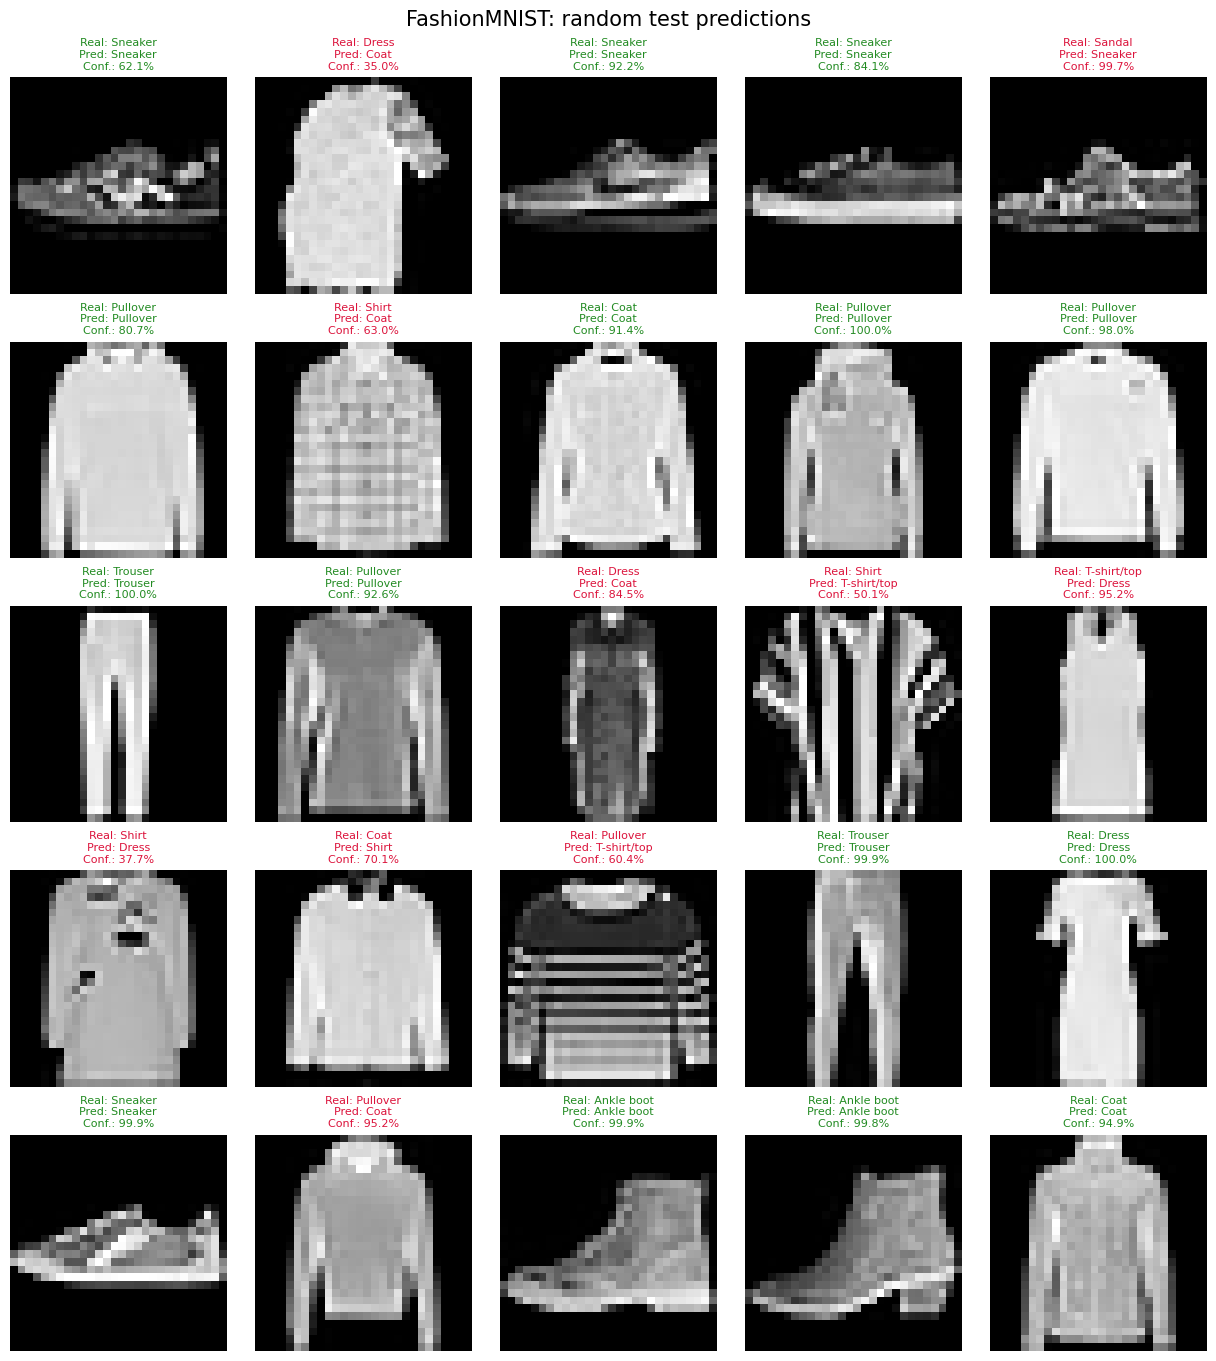

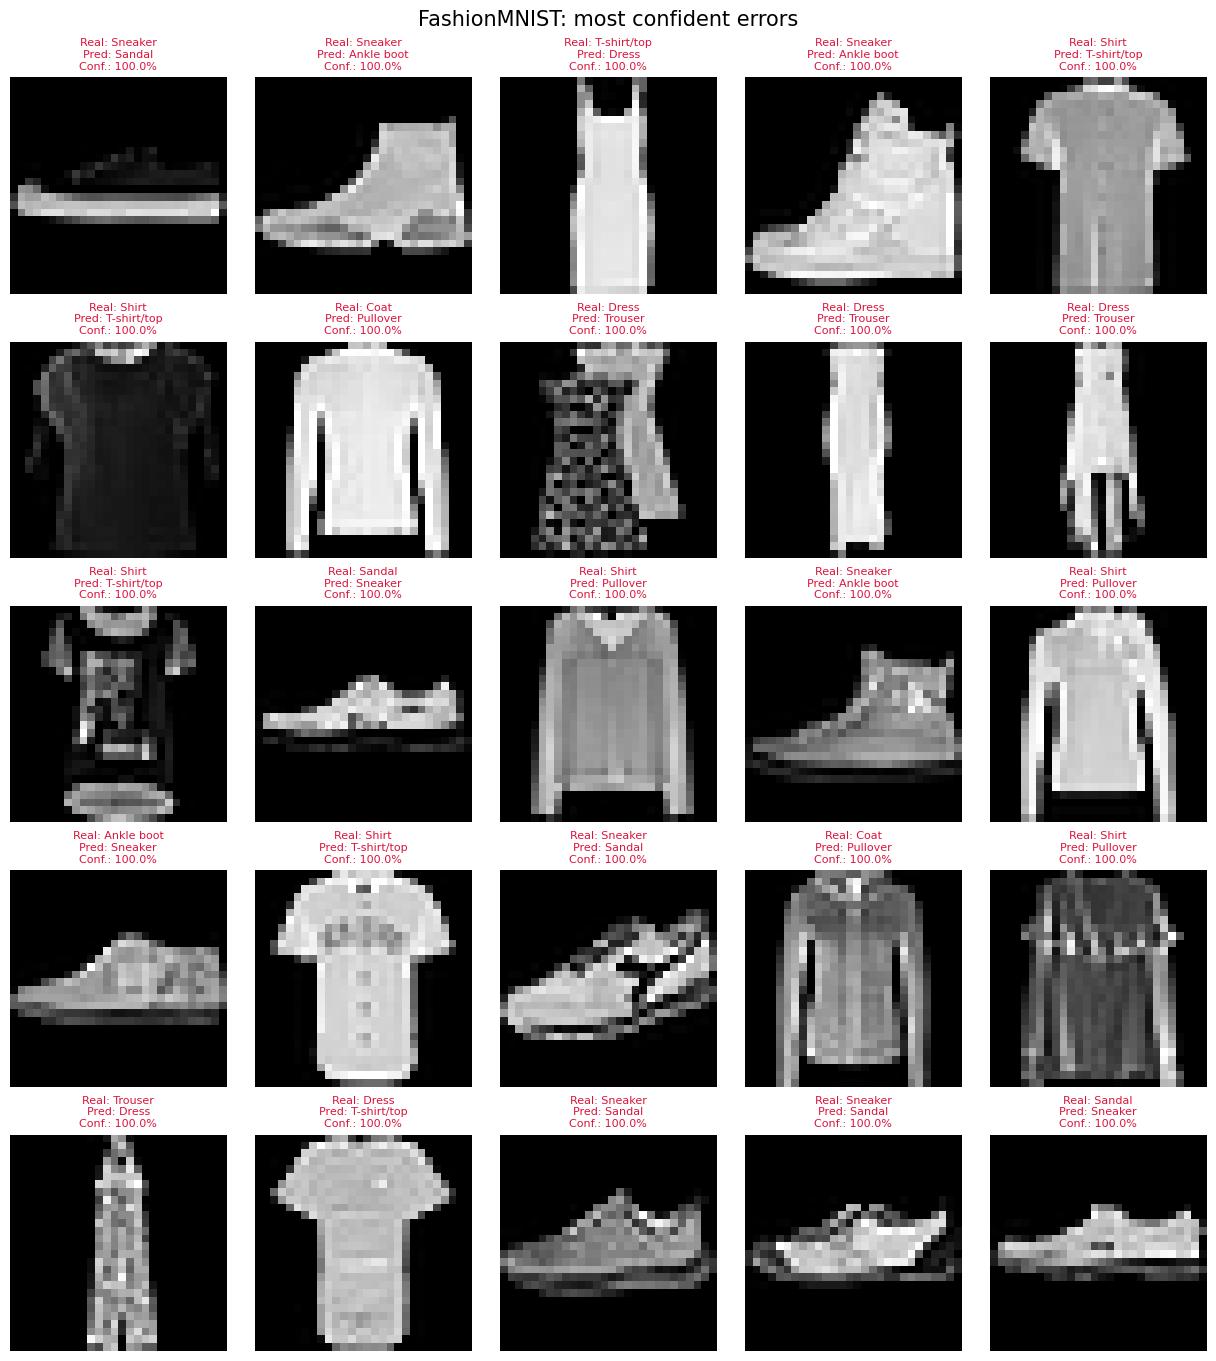

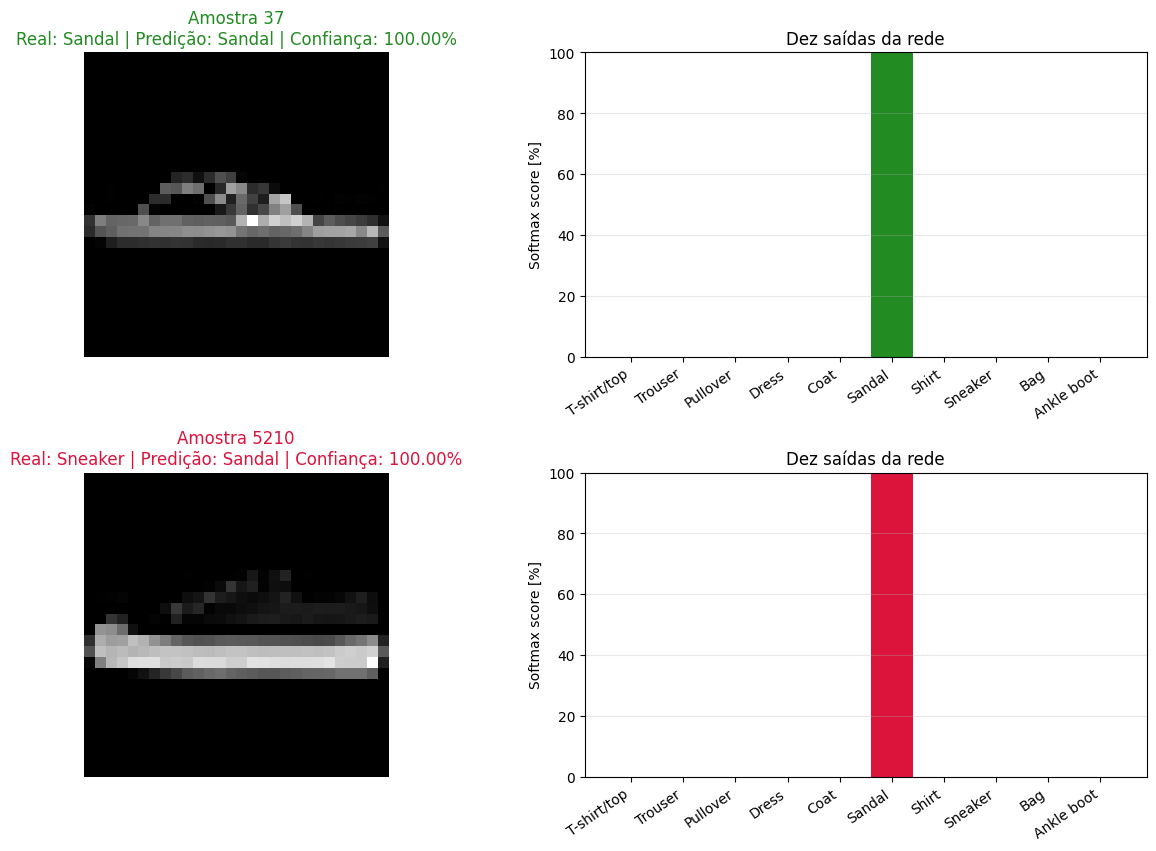

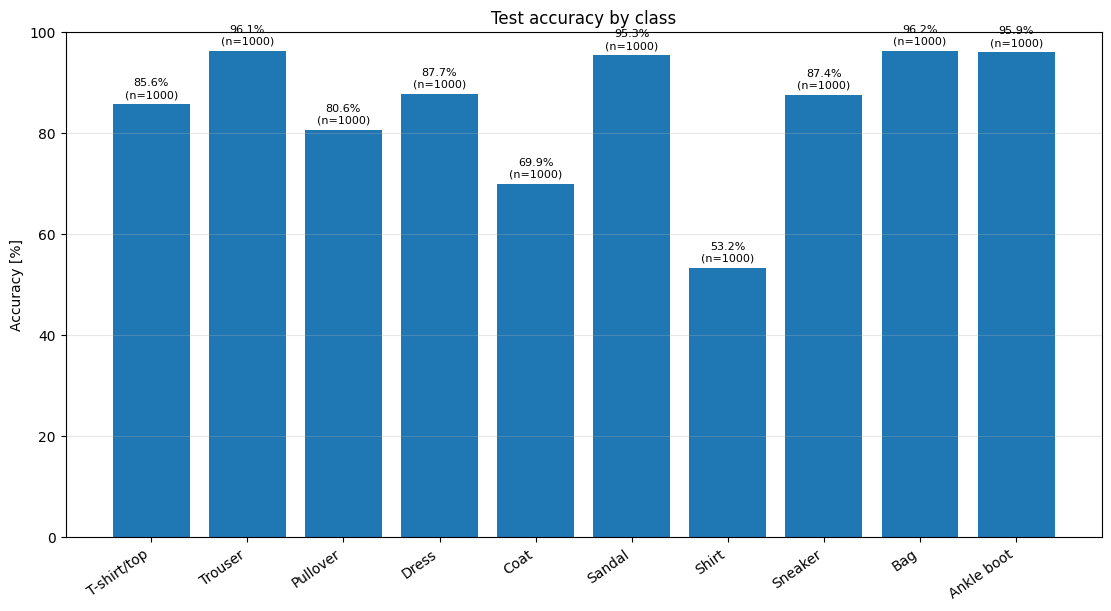

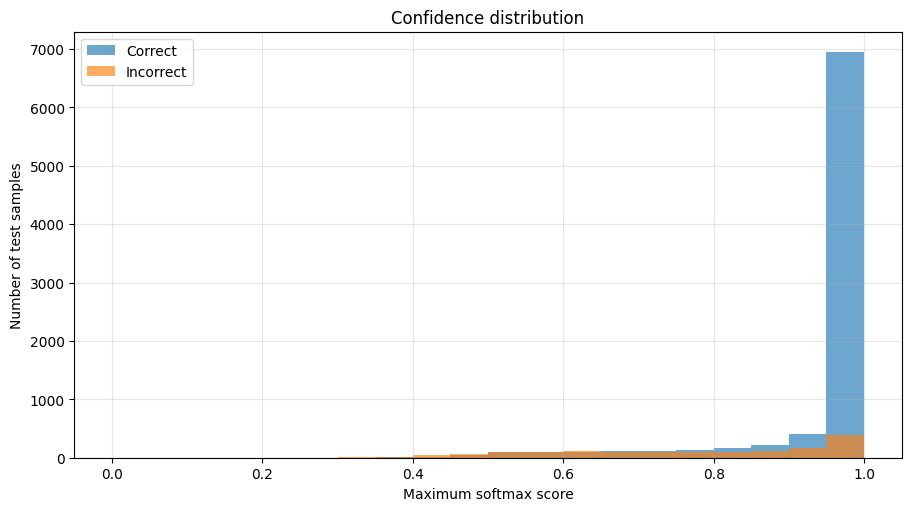


Figures and CSV saved in: C:\Users\erick.sousa\Downloads\TCC\Paper algorithm\dramzi_photonic_kan_results\FashionMNIST\prediction_visualizations


In [2]:
%run "visualize_trained_DRAMZI_KAN.py" --results-root "C:\Users\erick.sousa\Downloads\TCC\Paper algorithm\dramzi_photonic_kan_results" --dataset FashionMNIST --checkpoint best

PyTorch: 2.13.0+cpu
CUDA available: False
Device: cpu
Loaded checkpoint: C:\Users\erick.sousa\Downloads\TCC\Paper algorithm\dramzi_photonic_kan_results\MNIST\best_validation_model.pt
Checkpoint epoch: 9

PREDICTION VISUALIZATION: MNIST
Checkpoint: best
Test examples: 10000
Correct: 9674
Incorrect: 326
Recomputed test accuracy: 96.74%
Note: the maximum softmax score is a model confidence score; it is not automatically a calibrated probability.


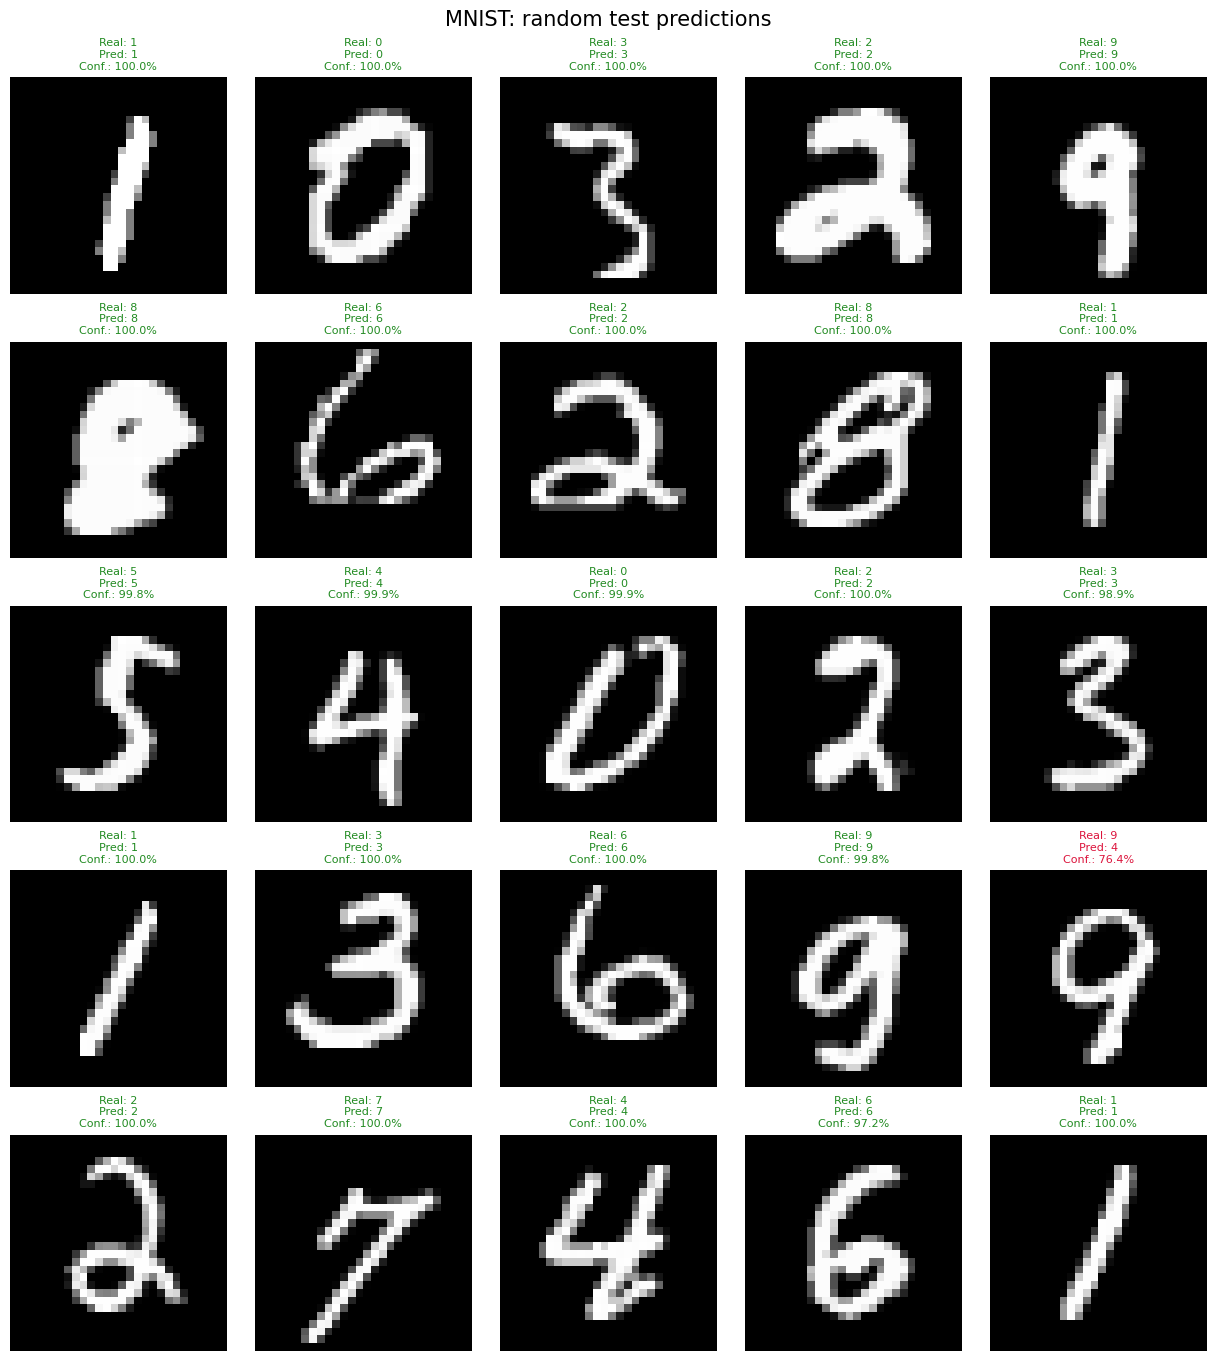

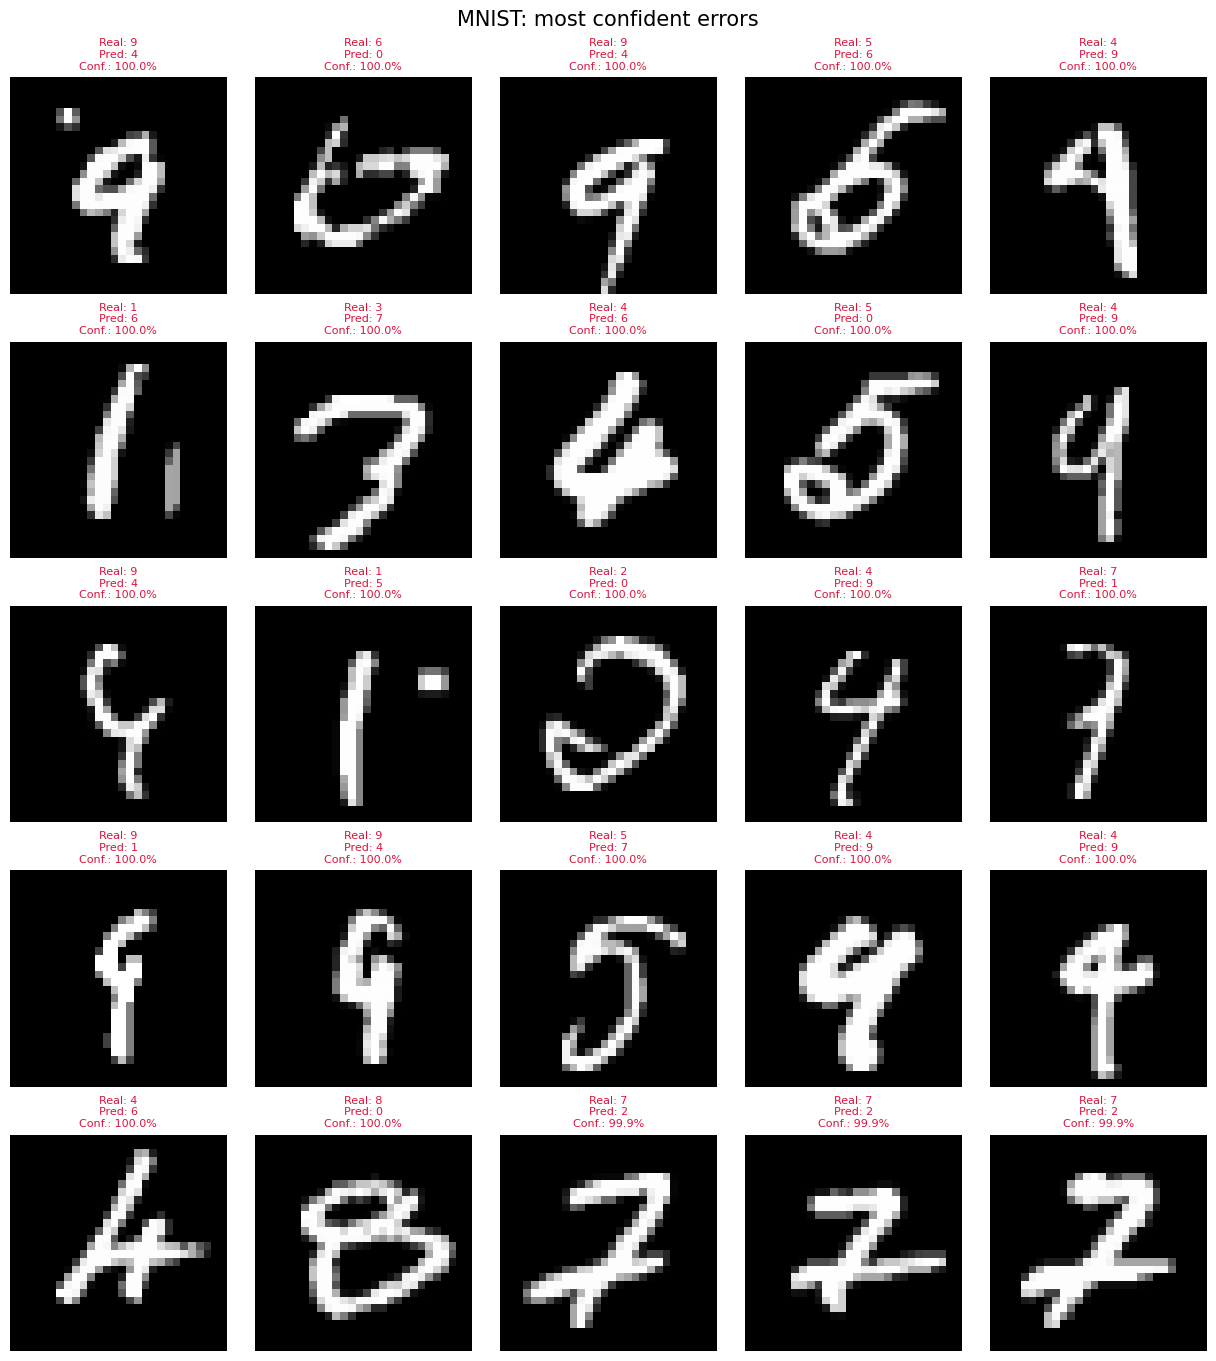

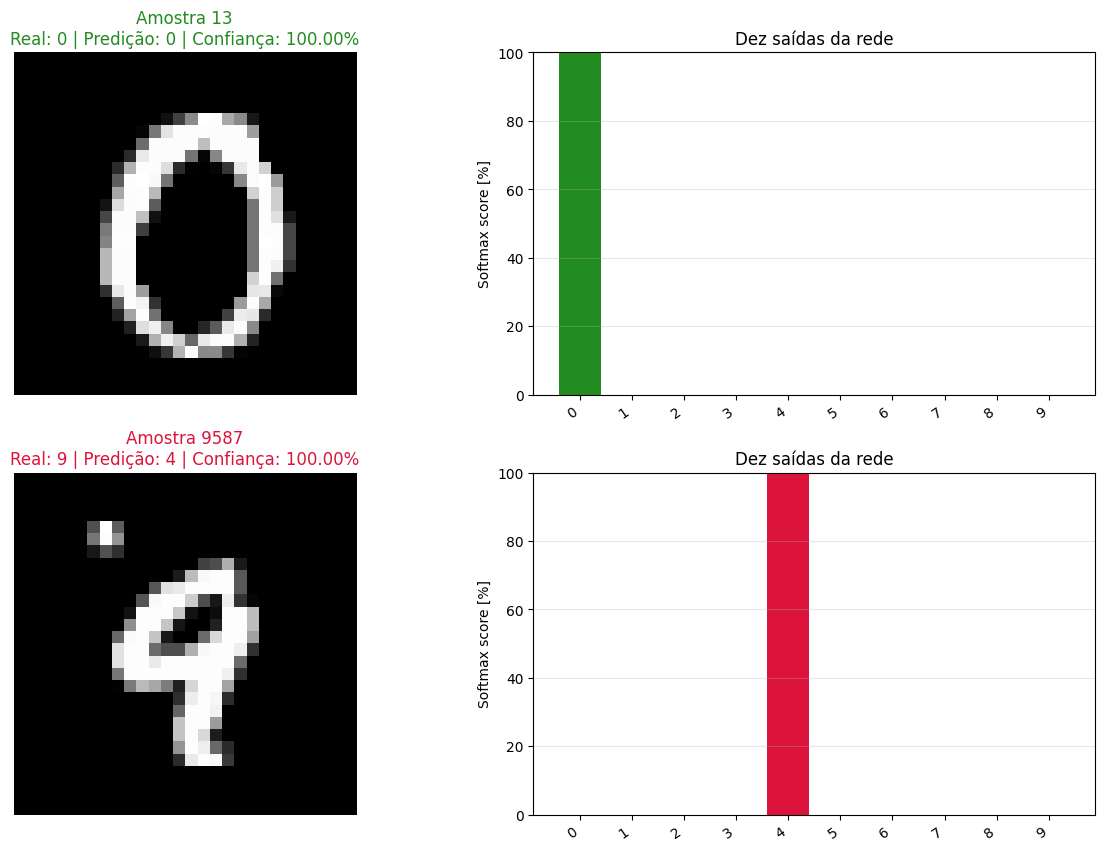

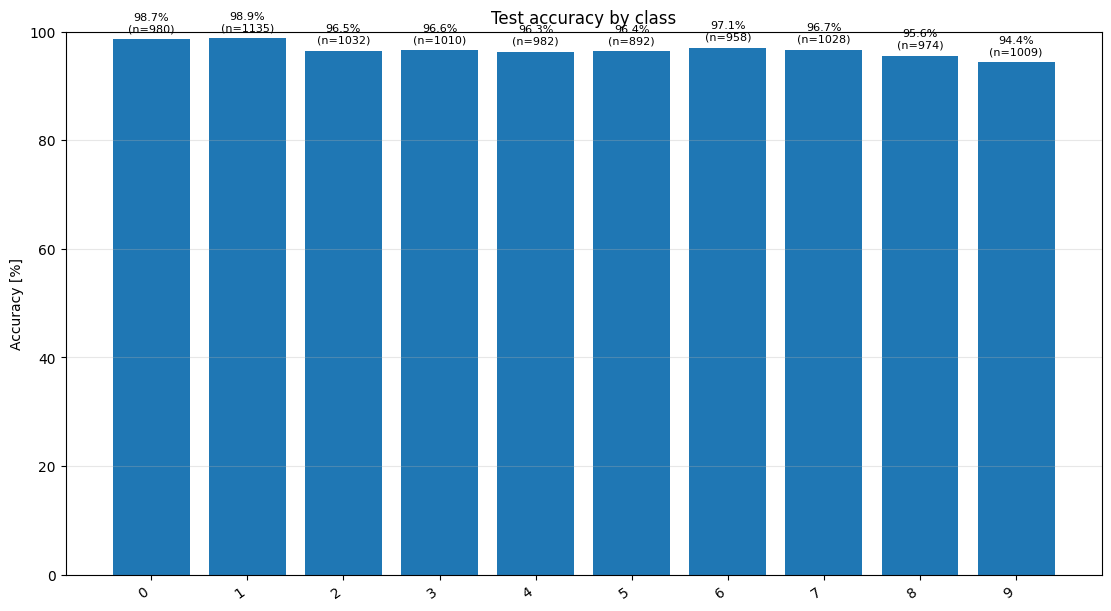

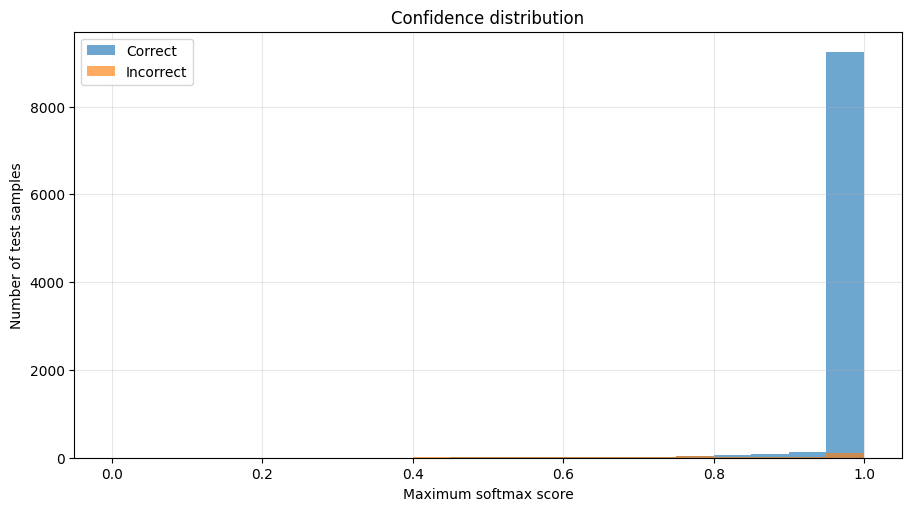


Figures and CSV saved in: C:\Users\erick.sousa\Downloads\TCC\Paper algorithm\dramzi_photonic_kan_results\MNIST\prediction_visualizations


In [3]:
%run "visualize_trained_DRAMZI_KAN.py" --results-root "C:\Users\erick.sousa\Downloads\TCC\Paper algorithm\dramzi_photonic_kan_results" --dataset MNIST --checkpoint best

In [1]:
%run "DRAMZI_MNIST_live_GUI.py" --results-root "C:\Users\erick.sousa\Downloads\TCC\Paper algorithm\dramzi_photonic_kan_results" --checkpoint best

D-RAMZI PHOTONIC KAN - INTERACTIVE MNIST GUI
PyTorch: 2.13.0+cpu
CUDA available: False
Results root: C:\Users\erick.sousa\Downloads\TCC\Paper algorithm\dramzi_photonic_kan_results
Device: cpu
Device name: CPU
Checkpoint: C:\Users\erick.sousa\Downloads\TCC\Paper algorithm\dramzi_photonic_kan_results\MNIST\best_validation_model.pt
Architecture: (784, 64, 10)
D-RAMZI bases: 8
LUT points: 4097
